In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob
import gseapy as gp

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [6]:
smad7 = sc.read('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/validation_flex_scvi_celltypist_smad7.h5ad')

In [8]:
smad7 = smad7[smad7.obs['sample']=='SMAD7']

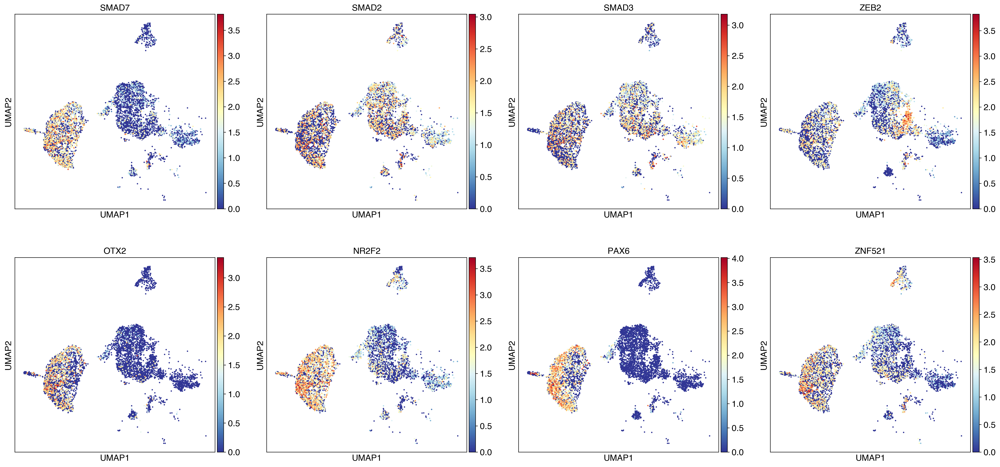

In [11]:
sc.pl.umap(smad7, color = ['SMAD7','SMAD2','SMAD3','ZEB2','OTX2','NR2F2','PAX6','ZNF521'])

## Cluster to find the neuronal cluster

In [15]:
sc.tl.leiden(smad7, resolution = 0.5)

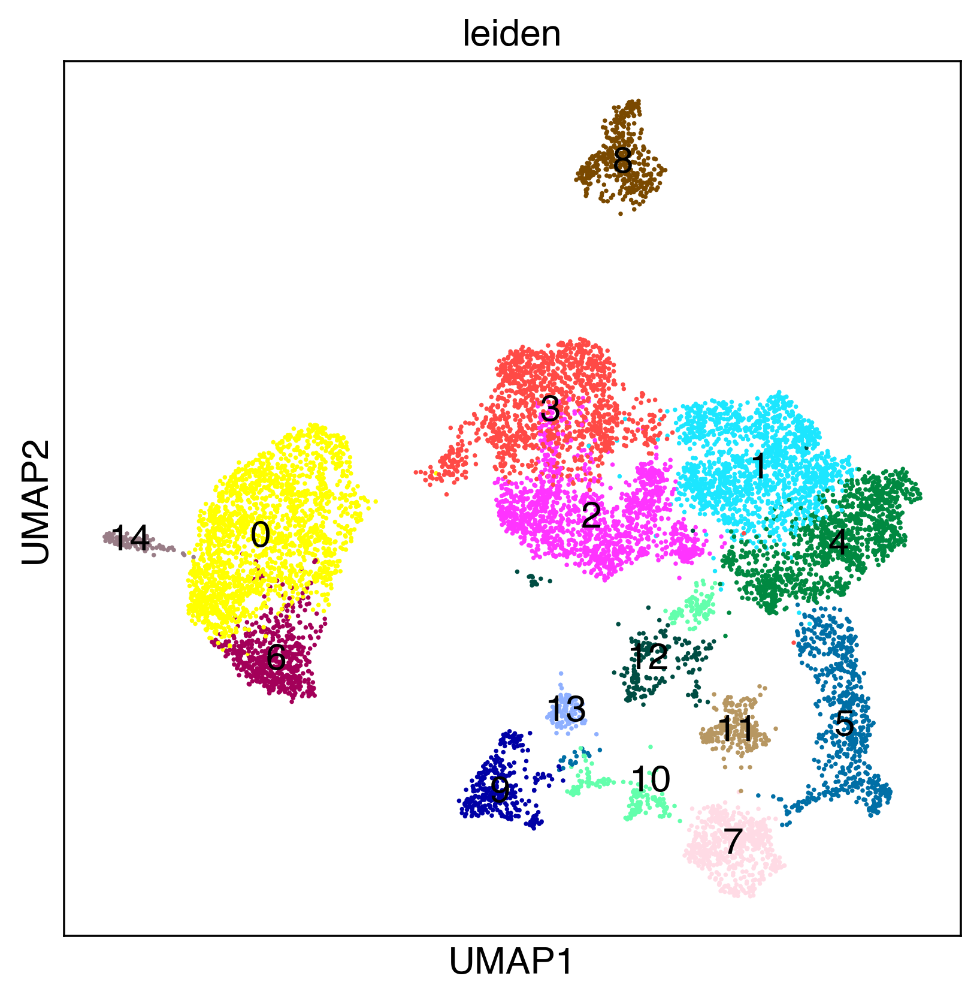

In [16]:
sc.pl.umap(smad7, color=['leiden'],legend_loc='on data')

In [17]:
neuron = smad7[smad7.obs['leiden'].isin(['0','6','14'])]
# recalculated neighbourhood and UMAP
sc.pp.neighbors(neuron, use_rep = 'X_scVI', random_state=1712)
sc.tl.umap(neuron,random_state=1712)

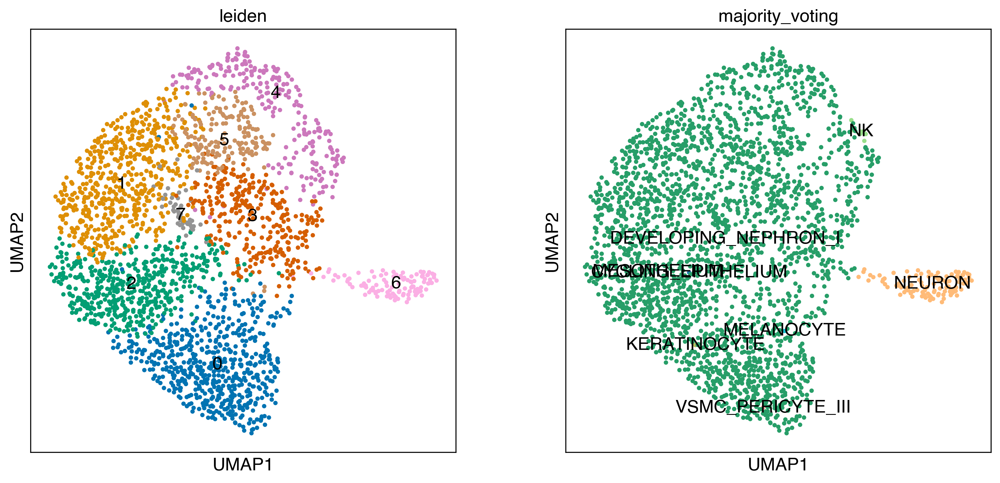

In [19]:
sc.tl.leiden(neuron, resolution = 0.5)
sc.pl.umap(neuron, color=['leiden','majority_voting'],legend_loc='on data')

In [20]:
# apart from cluster 6 which is neuroblast, others are radial glia
rg = neuron[neuron.obs['leiden']!='6']

# Celltypist using fetal brain dataset 

- Training data from https://www.science.org/doi/10.1126/science.adf1226#sec-2
- focus on different regions for radial glia

In [7]:
fetal_brain = sc.read('reference_data_brain/Radial_glia.h5ad')

In [7]:
pd.crosstab(fetal_brain.obs['CellClass'],fetal_brain.obs['Region'])

Region,Brain,Cerebellum,Diencephalon,Forebrain,Head,Hindbrain,Medulla,Midbrain,Pons,Telencephalon
CellClass,,,,,,,,,,
Radial glia,42562,22836,72022,81925,95,17126,33675,100722,21126,127819


In [8]:
fetal_brain.var_names = fetal_brain.var['Gene']

In [9]:
# subset to common genes only
fetal_brain = fetal_brain[:,fetal_brain.var_names.isin(smad7.var_names)]

In [10]:
sc.pp.normalize_per_cell(fetal_brain,counts_per_cell_after=1e4,key_n_counts='n_counts')

/tmp/ipykernel_2632902/1048551191.py:1: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(fetal_brain,counts_per_cell_after=1e4,key_n_counts='n_counts')
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:588: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_n_counts] = counts_per_cell
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:591: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [11]:
sc.pp.log1p(fetal_brain)

In [12]:
import celltypist
#from celltypist import models

In [13]:
# The `CellClass` in `fetal_brain.obs` will be used as cell type labels for training.
new_model = celltypist.train(fetal_brain, labels = 'Region', n_jobs = 10, feature_selection = True)

🍳 Preparing data before training
✂️ 323 non-expressed genes are filtered out
🔬 Input data has 519908 cells and 17538 genes
⚖️ Scaling input data
🏋️ Training data using SGD logistic regression
⚠️ Warning: it may take a long time to train this dataset with 519908 cells and 17538 genes, try to downsample cells and/or restrict genes to a subset (e.g., hvgs)
🔎 Selecting features
🧬 1433 features are selected
🏋️ Starting the second round of training
🏋️ Training data using logistic regression
✅ Model training done!


In [14]:
# Save the model.
new_model.write('write/model_from_fetal_brain_radial_glia.pkl')

### Use newly trained model to predict rg

In [21]:
predictions = celltypist.annotate(rg, model = 'write/model_from_fetal_brain_radial_glia.pkl', majority_voting = True)

🔬 Input data has 2422 cells and 18082 genes
🔗 Matching reference genes in the model
🧬 1433 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


In [22]:
# Get an `AnnData` with predicted labels embedded into the cell metadata columns.
rg = predictions.to_adata()

In [27]:
rg.obs['Trg_prob'] = predictions.probability_matrix.loc[:,'Telencephalon']
rg.obs['Drg_prob'] = predictions.probability_matrix.loc[:,'Diencephalon']
rg.obs['Frg_prob'] = predictions.probability_matrix.loc[:,'Forebrain']
rg.obs['Mrg_prob'] = predictions.probability_matrix.loc[:,'Midbrain']
rg.obs['Hrg_prob'] = predictions.probability_matrix.loc[:,'Hindbrain']

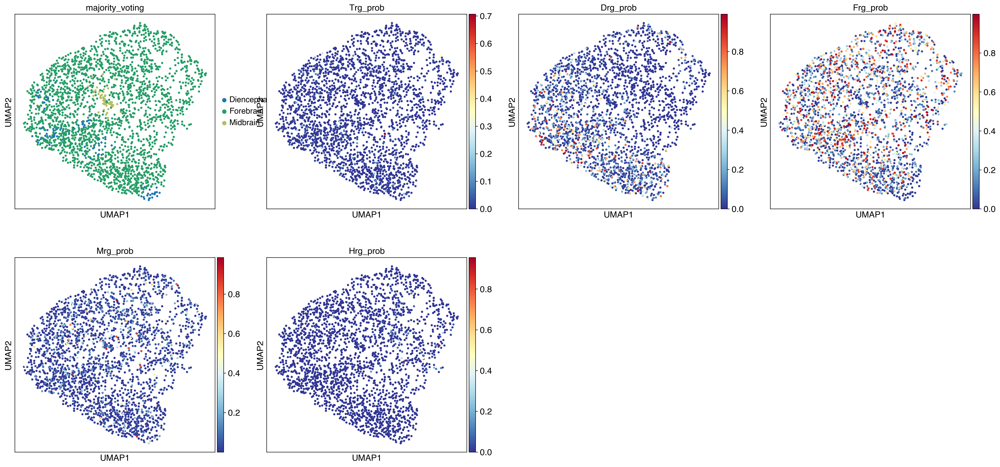

In [28]:
sc.pl.umap(rg, color=['majority_voting', 'Trg_prob',
                     'Drg_prob','Frg_prob','Mrg_prob','Hrg_prob'])

In [32]:
new_model.extract_top_markers("Forebrain", 20)

array(['HBA2', 'TTR', 'FOS', 'VCL', 'ADGRG7', 'C1orf61', 'MT-CO3',
       'EEF1G', 'IGDCC3', 'MT-ND2', 'TUBB4B', 'MT-ND1', 'DLK1', 'PPDPF',
       'ALX1', 'MYO1E', 'HBB', 'COTL1', 'TMSB10', 'NR2F2'], dtype=object)

In [33]:
new_model.extract_top_markers("Telencephalon", 20)

array(['EMX2', 'EIF1AY', 'HSPA1A', 'HES1', 'MT-ND5', 'HES5', 'NLGN4Y',
       'IRX5', 'NFIA', 'FGF17', 'MAP1B', 'ID4', 'CD81', 'USP9Y', 'RSPO2',
       'HSP90AA1', 'NNAT', 'NKX6-2', 'EIF4A1', 'HMGA2'], dtype=object)